# 5. Tables and figures
Summary tables and all figures of the paper.

Run the notebooks 1 to 4 first. The figures use the font Liberation Sans if it is installed (`apt-get install -y fonts-liberation`), otherwise DejaVu Sans.

In [1]:
import torch
import pandas as pd

from constants import *
from utils import get_device
from dataset import load_pieces, get_duration_values
from disk_utils import load_results, load_json
from faithfulness import (
    load_deletion_tests,
    load_pitch_matched_deletion_tests,
    compare_with_pitch_matched,
    pitch_matched_overlap
)
from attention_inspector import AttentionInspector
from plot_manager import PlotManager
from result_tables import (
    per_seed_table,
    summary_table,
    paired_tests,
    paired_difference,
    pooled_report,
    list_confusions,
    group_errors,
    write_summary_files
)
from extra_checks import (
    near_duplicate_check,
    count_test_occurrences,
    transposition_predictions,
    prediction_shares,
    compare_with_earlier_trainings
)

In [2]:
USE_GPU = True
device = get_device(USE_GPU)
print(device)

# QUICK_TEST = True reads the dry run in results_quick_test/ and writes
# the figures to figs_quick_test/.
QUICK_TEST = False

if QUICK_TEST:
    results_dir = QUICK_TEST_RESULTS_DIR
    figs_dir = QUICK_TEST_FIGS_DIR
else:
    results_dir = RESULTS_DIR
    figs_dir = FIGS_DIR

# set to False to look at the figures without writing the files
SAVE_FIGS = True

cuda


## Tables

All accuracies as text files: `summary.txt`, `full_pooled.txt`, `paired_tests.txt`.

In [3]:
write_summary_files(results_dir)

Wrote summary.txt, full_pooled.txt and paired_tests.txt to results/


Mean ± 95% CI over the five splits (Tables 4 and 7).

In [4]:
results = load_results(results_dir)
per_seed = per_seed_table(results)
summary = summary_table(per_seed)

pd.set_option("display.max_rows", 200)
summary[["tag", "perturbation", "n", "acc_mean", "acc_ci", "f1_mean", "f1_ci"]]

,tag,perturbation,n,acc_mean,acc_ci,f1_mean,f1_ci
0,bigram__logreg,,5,0.900571,0.008090,0.896318,0.010570
1,bigram__svm_rbf,,5,0.915429,0.019038,0.912351,0.022586
2,full,,5,0.920000,0.029254,0.914877,0.031895
3,full,shuffle,5,0.801143,0.023745,0.796994,0.025061
4,full,transpose+13,5,0.169143,0.049311,0.080260,0.033280
5,full,transpose+4,5,0.030857,0.016334,0.015126,0.012548
6,full,transpose+5,5,0.101714,0.020318,0.047696,0.022938
7,full,transpose+9,5,0.056000,0.038667,0.017423,0.011787
8,full,transpose-13,5,0.068571,0.012289,0.015989,0.005624
9,full,transpose-4,5,0.070857,0.048797,0.042353,0.035360


Paired comparison with the proposed model (the Δ, confidence-interval and p columns of Tables 4, 7 and B2). `p_corrected` is the corrected resampled t-test, which takes into account that the splits share pieces.

In [5]:
paired_tests(per_seed, reference_tag="full")

,tag,perturbation,n_splits,acc_mean,delta_points,ci_low,ci_high,p_paired_t,p_corrected,all_splits_same_sign
0,bigram__logreg,,5,90.057143,-1.942857,-4.274585,0.388871,8.172591e-02,1.836549e-01,False
1,bigram__svm_rbf,,5,91.542857,-0.457143,-3.762329,2.848043,7.205095e-01,8.030252e-01,False
2,full,shuffle,5,80.114286,-11.885714,-14.260230,-9.511199,1.554355e-04,6.463347e-04,True
3,full,transpose+13,5,16.914286,-75.085714,-79.419031,-70.752397,1.116857e-06,4.799747e-06,True
4,full,transpose+4,5,3.085714,-88.914286,-92.688784,-85.139787,3.273929e-07,1.408982e-06,True
5,full,transpose+5,5,10.171429,-81.828571,-83.366779,-80.290364,1.260382e-08,5.431542e-08,True
6,full,transpose+9,5,5.600000,-86.400000,-92.949164,-79.850836,3.316869e-06,1.422262e-05,True
7,full,transpose-13,5,6.857143,-85.142857,-88.760725,-81.524989,3.286510e-07,1.414393e-06,True
8,full,transpose-4,5,7.085714,-84.914286,-88.031342,-81.797229,1.831238e-07,7.884322e-07,True
9,full,transpose-5,5,10.857143,-81.142857,-87.817648,-74.468066,4.596287e-06,1.969018e-05,True


Per-makam precision, recall and F1 of the proposed model, pooled over the five test subsets (Table 5).

In [6]:
# the unperturbed runs of the proposed model
main_results = []
for result in load_results(results_dir, "full"):
    if not result.get("perturbation"):
        main_results.append(result)

report, cm = pooled_report(main_results)
report.round(2)

,precision,recall,f1-score,support
hicaz,0.99,0.99,0.99,120.00
nihavent,0.98,0.98,0.98,100.00
ussak,0.90,0.83,0.87,90.00
rast,0.90,0.95,0.93,85.00
huzzam,0.94,0.94,0.94,70.00
segah,0.94,0.91,0.93,70.00
huseyni,0.77,0.66,0.71,70.00
mahur,0.93,0.97,0.95,65.00
hicazkar,0.98,0.98,0.98,60.00
kurdilihicazkar,0.98,0.96,0.97,50.00


Confusions of the proposed model, most frequent first (Table 6).

In [7]:
for true_makam, predicted_makam, count in list_confusions(cm):
    if count >= 2:
        print(f"{true_makam:>16s} -> {predicted_makam:<16s} {count}")

         huseyni -> muhayyer         15
           ussak -> huseyni          7
           ussak -> muhayyer         5
         huseyni -> ussak            5
        muhayyer -> huseyni          5
          huzzam -> segah            4
           segah -> huzzam           3
         huseyni -> rast             3
           ussak -> rast             2
            rast -> mahur            2
           segah -> rast             2
            saba -> ussak            2


Errors inside the group Uşşak–Hüseyni–Muhayyer and between Segah and Hüzzam, for every model.

In [8]:
group_errors(results)

,tag,errors,within_group,segah_huzzam,recall_huseyni,recall_muhayyer
0,bigram__logreg,87,41,9,0.614286,0.72
1,bigram__svm_rbf,74,36,9,0.700000,0.78
2,full,70,38,7,0.657143,0.86
3,full_unpacked,73,40,9,0.585714,0.80
4,hist53_cnt__knn,119,57,11,0.500000,0.44
5,hist53_cnt__logreg,93,41,6,0.714286,0.50
6,hist53_cnt__rf,102,46,7,0.628571,0.54
7,hist53_cnt__svm_rbf,90,43,10,0.671429,0.60
8,hist53_dur__knn,100,54,10,0.671429,0.50
9,hist53_dur__logreg,66,34,7,0.814286,0.66


Does the duration weighting of the pitch histogram help? Paired difference between the duration-weighted and the count histogram (logistic regression), in percentage points, and the p-value of the paired t-test.

In [9]:
paired_difference(per_seed, "hist53_dur__logreg", "hist53_cnt__logreg")

(np.float64(3.0857142857142854), np.float64(0.0034536146280531536))

## Further checks reported in the paper
Pieces with the same opening (mostly an aranağme that is also the beginning of a song): how many test classifications have such a piece in the training subset of the same split, and what is the accuracy without them?

In [10]:
near_duplicate_check(
    tags=["full", "hist53_dur__logreg", "hist53_dur__svm_rbf", "hist_abs_dur__svm_rbf"],
    results_dir=results_dir
)

,tag,n_groups,n_affected,accuracy_all,accuracy_without_affected
0,full,27,27,92.000000,91.745283
1,hist53_dur__logreg,27,27,92.457143,92.688679
2,hist53_dur__svm_rbf,27,27,92.571429,92.806604
3,hist_abs_dur__svm_rbf,27,27,93.028571,93.042453


In how many splits is a piece in the test subset? (number of splits: number of pieces)

In [11]:
count_test_occurrences()

{1: 468, 2: 159, 3: 27, 4: 2}

Predictions for transposed test pieces. The model collapses onto a few makams: share of all predictions that go to the three most predicted makams, for every transposition.

In [12]:
for kommas in TRANSPOSITIONS:
    prediction_table = transposition_predictions("full", kommas, results_dir=results_dir)
    shares = prediction_shares(prediction_table)
    top_three = ", ".join(f"{makam} {share:.2f}" for makam, share in shares.head(3).items())
    print(f"{kommas:+3d} kommas | top three: {shares.head(3).sum():.2f} | {top_three}")

 +4 kommas | top three: 0.92 | kurdilihicazkar 0.59, nihavent 0.24, huzzam 0.09
 +5 kommas | top three: 0.93 | hicazkar 0.73, huzzam 0.14, hicaz 0.05
 +9 kommas | top three: 0.86 | mahur 0.45, hicaz 0.36, nihavent 0.05
+13 kommas | top three: 0.87 | huzzam 0.53, kurdilihicazkar 0.23, nihavent 0.11
 -4 kommas | top three: 0.89 | hicazkar 0.57, mahur 0.21, kurdilihicazkar 0.10
 -5 kommas | top three: 0.73 | segah 0.32, kurdilihicazkar 0.27, rast 0.15
 -9 kommas | top three: 0.88 | kurdilihicazkar 0.50, hicazkar 0.31, nihavent 0.07
-13 kommas | top three: 0.89 | mahur 0.68, kurdilihicazkar 0.12, nihavent 0.09


Hicaz pieces lowered by 9 kommas (a whole tone) and Hicazkar pieces raised by 9 kommas: what are they predicted as?

In [13]:
lowered = transposition_predictions("full", -9, results_dir=results_dir)
raised = transposition_predictions("full", 9, results_dir=results_dir)

print("hicaz, -9 kommas:")
print(lowered.loc["hicaz"][lowered.loc["hicaz"] > 0])
print()
print("hicazkar, +9 kommas:")
print(raised.loc["hicazkar"][raised.loc["hicazkar"] > 0])

hicaz, -9 kommas:
predicted
hicazkar    119
rast          1
Name: hicaz, dtype: int64

hicazkar, +9 kommas:
predicted
hicaz    59
mahur     1
Name: hicazkar, dtype: int64


## Figures

In [14]:
pm = PlotManager(figs_dir=figs_dir)

pieces, labels, vocab = load_pieces()
dur_values = get_duration_values(vocab)

Figure 1: pieces per makam

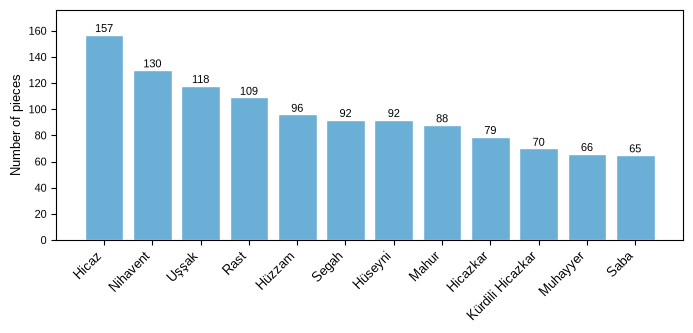

In [15]:
pm.plot_makam_distribution(labels, save_fig=SAVE_FIGS)

Figure 2: notes per piece

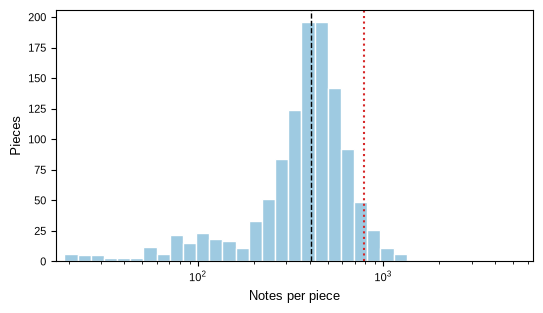

Lengths | min: 19, median: 407.5, mean: 422.1, 95th percentile: 783.9, max: 5832


In [16]:
pm.plot_length_histogram(pieces, save_fig=SAVE_FIGS)

Figure 4: overview of all accuracies

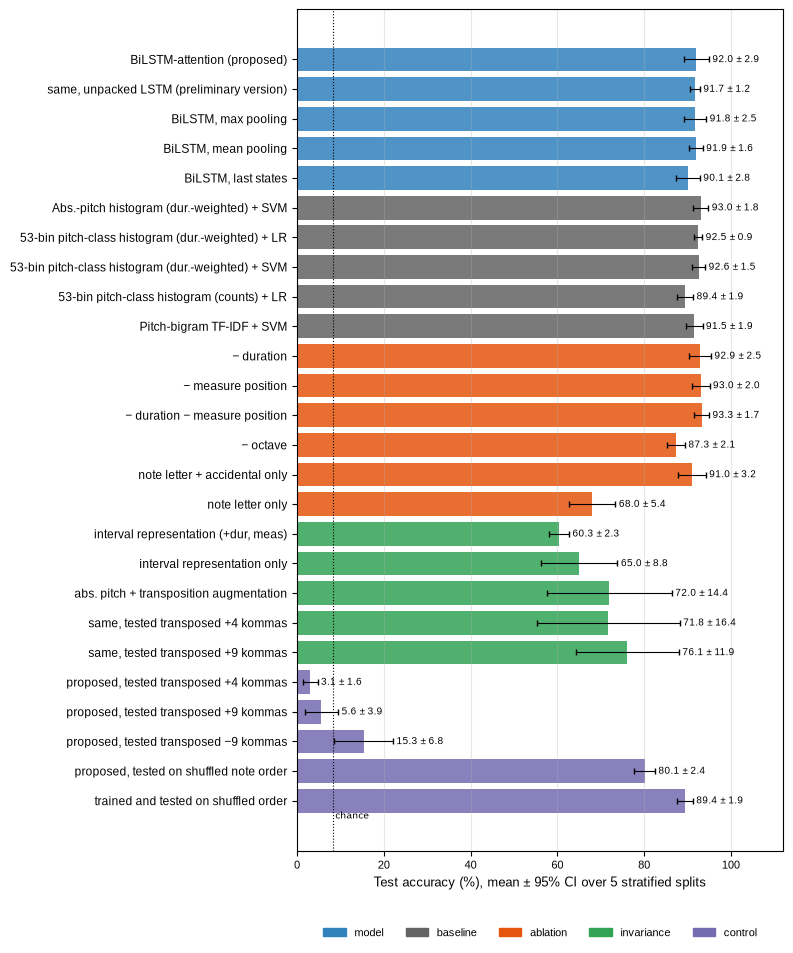

In [17]:
pm.plot_results_overview(summary, save_fig=SAVE_FIGS)

Figure 5: confusion matrix of the proposed model

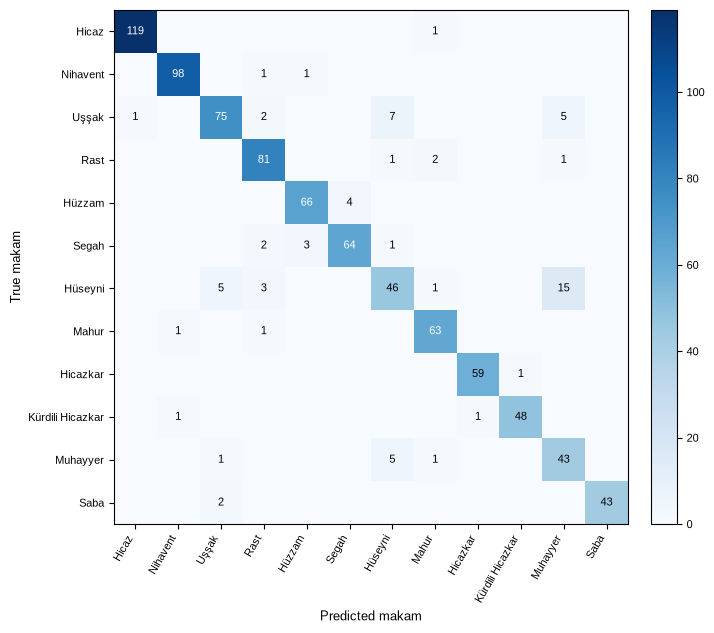

In [18]:
pm.plot_confusion_matrix(cm.values, save_fig=SAVE_FIGS)

Figure 6: deletion tests

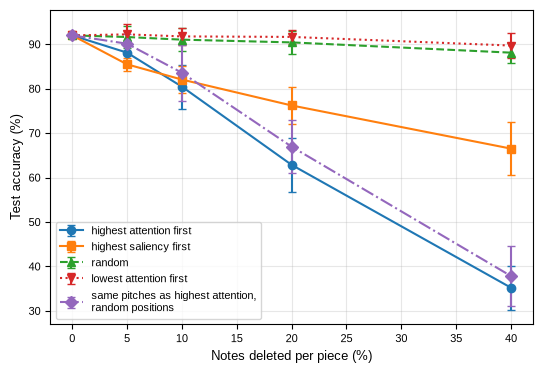

In [19]:
curves, deletion_summary = load_deletion_tests("full", results_dir)

# control: the same pitches as the most attended notes, at random positions
_, pitch_matched_summary = load_pitch_matched_deletion_tests("full", results_dir)

pm.plot_deletion_curves(
    curves,
    deletion_summary,
    tag="full",
    pitch_matched_summary=pitch_matched_summary,
    save_fig=SAVE_FIGS
)

Deletion of the most attended notes against the control (same pitches, random positions): accuracy lost by each, the share of the loss that the control reproduces, and the paired t-test of the two over the splits.

In [20]:
pitch_matched_curves, _ = load_pitch_matched_deletion_tests("full", results_dir)
compare_with_pitch_matched(pitch_matched_curves)

,frac,acc_attn_top,acc_pitch_matched,drop_attn_top,drop_pitch_matched,share_reproduced,difference,p_paired_t,n_seeds_attn_lower
0,0.05,88.114286,90.125714,3.885714,1.874286,0.482353,2.011429,0.051729,4
1,0.10,80.457143,83.588571,11.542857,8.411429,0.728713,3.131429,0.234868,4
2,0.20,62.857143,66.948571,29.142857,25.051429,0.859608,4.091429,0.106235,5
3,0.40,35.200000,37.828571,56.800000,54.171429,0.953722,2.628571,0.100826,4


Rank correlation of attention and gradient saliency within the pieces, mean over the splits.

In [21]:
correlations = []
for seed in SEEDS:
    seed_result = load_json(f"{results_dir}faithfulness/full_seed{seed}.json")
    correlations.append(seed_result["spearman_attn_saliency_mean"])

print(f"Spearman, mean over the splits: {sum(correlations) / len(correlations):.3f}")

Spearman, mean over the splits: 0.429


Figure 7 and Figure C1: pitch enrichment per makam, ordered by frequency and by pitch

In [22]:
ai = AttentionInspector(device, results_dir=results_dir)

note_table = ai.load_note_table("full")
enrichment = ai.pitch_enrichment(note_table)

How similar are the notes deleted by the control to the most attended notes? The larger the deleted fraction, the more the two sets coincide, so the control says most at the small fractions.

In [23]:
pitch_matched_overlap(note_table)

,frac,expected_overlap,forced_identical
0,0.05,0.395807,0.067131
1,0.10,0.545495,0.114419
2,0.20,0.668208,0.211483
3,0.40,0.758992,0.347759


Further entries of the attention report (`attention/full_report.json`, written by notebook 4): the Friedman test over the four shorter duration bins, the tests with one value per distinct piece, the permutation check of the test on the high-attention notes, measure position without the rests, and the checks on the enrichment.

In [24]:
report = load_json(f"{results_dir}attention/full_report.json")

duration = report["duration_all"]
measure = report["rest_and_measure"]

print("Duration, four shorter bins:", duration["friedman_four_shorter_bins"])
print()
print("Duration, distinct pieces:", duration["distinct_pieces"])
print()
print("Note-level median by bin:", duration["note_level"]["median_norm_attn_by_bin"])
print()
print("High-attention notes, permutation check:", report["high_share_permutation"])
print()
print("Share of rests by measure position:", measure["rest_share_by_measure_position"])
print()
print("Measure position without rests:", measure["measure_position_without_rests"])
print()
print("Measure position, distinct pieces:", measure["measure_position_distinct_pieces"])
print()
print("Measure position, distinct pieces, without rests:", measure["measure_position_distinct_pieces_without_rests"])
print()
print("Enrichment checks:", report["enrichment_checks"])

Duration, four shorter bins: {'n': 398, 'chi2': 32.20402010050202, 'p': 4.7401079651474846e-07, 'kendall_W': 0.02697154112269851, 'median': {'Very short (≤1/16)': 0.2770553529262543, 'Short (1/16–3/16]': 0.31319858133792877, 'Medium (3/16–3/8]': 0.33178798109292984, 'Long (3/8–3/4]': 0.3661513179540634}, 'mean': {'Very short (≤1/16)': 0.4821507159521658, 'Short (1/16–3/16]': 0.3470799350954859, 'Medium (3/16–3/8]': 0.4755312264405528, 'Long (3/8–3/4]': 0.6676798991519073}}

Duration, distinct pieces: {'five_bins': {'n': 94, 'chi2': 4.91063829787231, 'p': 0.2965900718844426, 'kendall_W': 0.013060208239022103, 'median': {'Very short (≤1/16)': 0.27910522371530533, 'Short (1/16–3/16]': 0.2950144074857235, 'Medium (3/16–3/8]': 0.32588429749011993, 'Long (3/8–3/4]': 0.29313189908862114, 'Very long (>3/4)': 0.35022205114364624}, 'mean': {'Very short (≤1/16)': 0.39948575458355606, 'Short (1/16–3/16]': 0.34294899811651164, 'Medium (3/16–3/8]': 0.4287461275763228, 'Long (3/8–3/4]': 0.53273916130

Are the pitch findings the same in the two earlier trainings of the same model (`results/earlier_trainings/`)? Rank correlation of the enrichment values, and the duration effect of the earlier trainings.

In [25]:
compare_with_earlier_trainings(enrichment)

,training,n_pitches,spearman_enrichment,max_attn_share_difference,duration_kendall_W_five_bins,duration_friedman_p_five_bins
0,prelim,84,0.983639,0.137663,0.010034,0.273478
1,first_deterministic,84,0.992548,0.094661,0.053064,0.000018


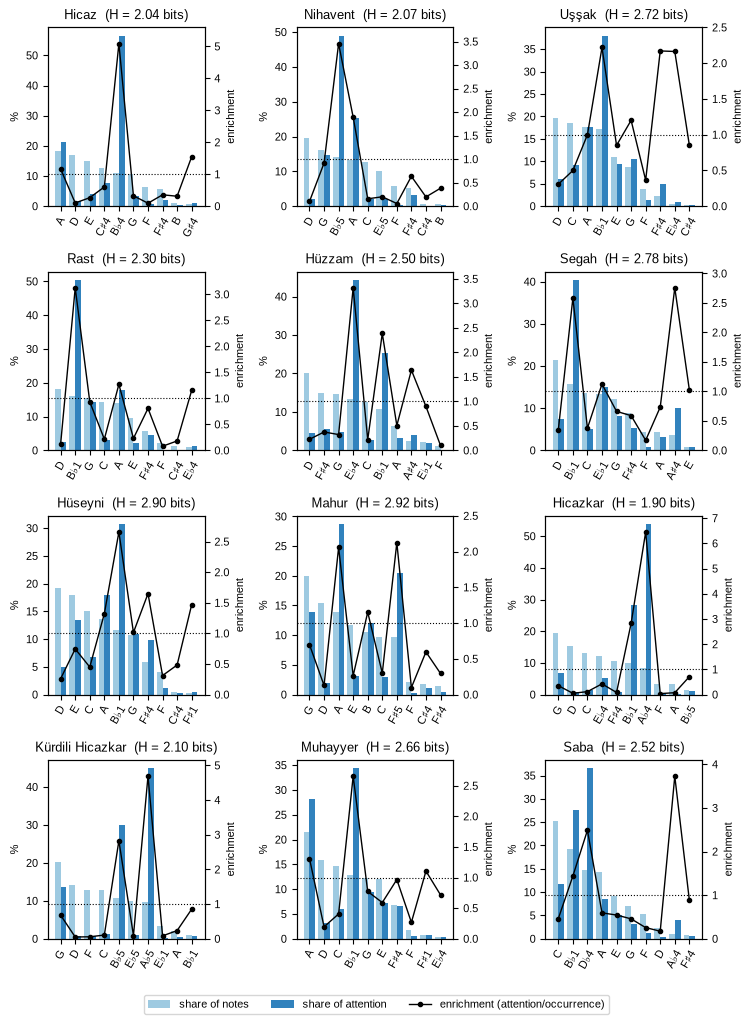

In [26]:
pm.plot_pitch_enrichment(enrichment, tag="full", pitch_order=False, save_fig=SAVE_FIGS)

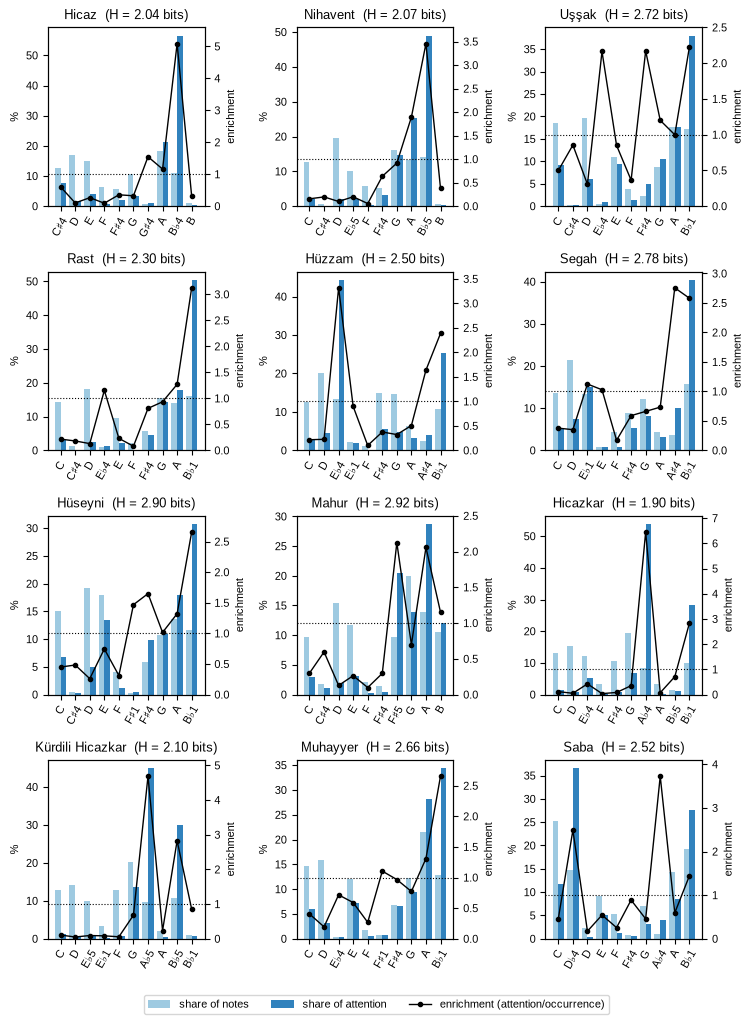

In [27]:
pm.plot_pitch_enrichment(enrichment, tag="full", pitch_order=True, save_fig=SAVE_FIGS)

Figure 8: attention over one test piece

hicaz--sarki--duyek--bogazici_sen--alaeddin_yavasca.txt | notes: 296 | predicted: hicaz
the 15 most attended notes carry 40% of the attention


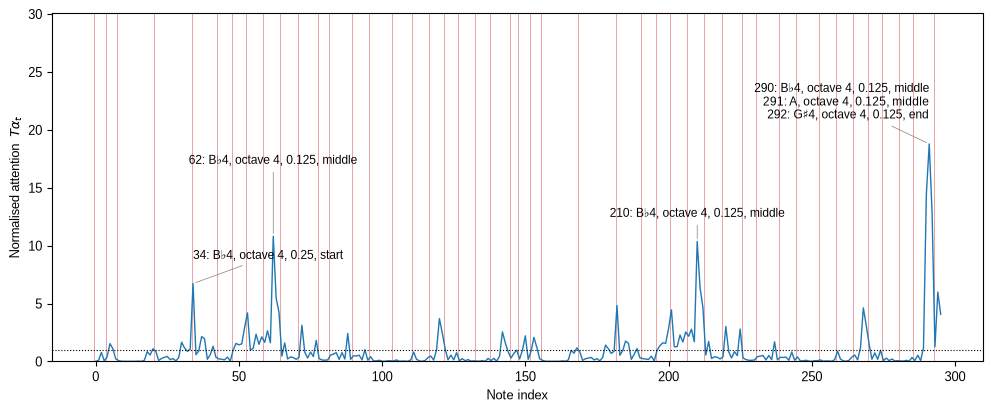

Highest peaks (index: pitch, octave, relative duration, measure position | T*alpha)
  34: Bb4, octave 4, 0.25, start | 6.73
  62: Bb4, octave 4, 0.125, middle | 10.81
  210: Bb4, octave 4, 0.125, middle | 10.36
  290: Bb4, octave 4, 0.125, middle | 14.44
  291: A, octave 4, 0.125, middle | 18.79
  292: G#4, octave 4, 0.125, end | 12.83


In [28]:
piece, attn, predicted_makam = ai.get_piece_attention(
    tag="full",
    seed=EXAMPLE_PIECE_SEED,
    piece_name=EXAMPLE_PIECE
)
print(piece["f_name"], "| notes:", len(attn), "| predicted:", predicted_makam)

# how concentrated is the attention? share of the 5% most attended notes
num_top = int(round(0.05 * len(attn)))
top_share = sorted(attn, reverse=True)[:num_top]
print(f"the {num_top} most attended notes carry {100 * sum(top_share):.0f}% of the attention")

# the pitch names are written as in the scores of the makam of the piece
# ("hicaz--sarki--..." -> "hicaz")
makam = piece["f_name"].split("--")[0]

pm.plot_example_piece(
    piece["notes"],
    attn,
    dur_values,
    ai.spelling_map[makam],
    save_fig=SAVE_FIGS
)

Figure 9: attention by relative duration (rests left out)

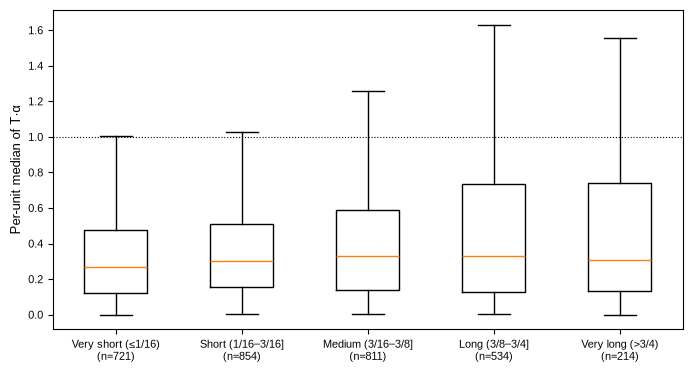

In [29]:
pitched_notes = note_table[~note_table["is_rest"]]
unit_by_duration = ai.unit_by_duration_bin(pitched_notes, "norm_attn")

pm.plot_attention_by_duration(unit_by_duration, tag="full", save_fig=SAVE_FIGS)

Figure 10: attention by position in the measure, for the proposed model and for the model without the measure-position input

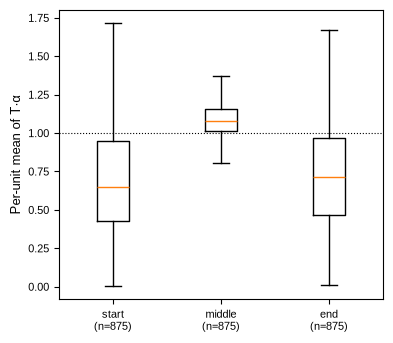

In [30]:
unit_by_position = ai.unit_by_measure_position(note_table, "norm_attn")
pm.plot_attention_by_measure_position(unit_by_position, tag="full", save_fig=SAVE_FIGS)

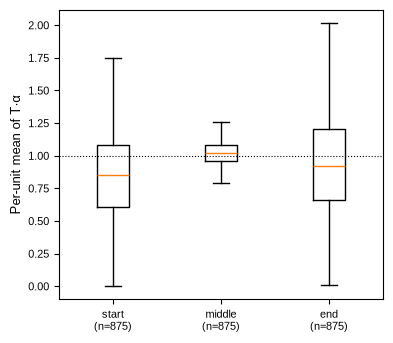

In [31]:
note_table_no_meas = ai.load_note_table("no_meas")
unit_by_position_no_meas = ai.unit_by_measure_position(note_table_no_meas, "norm_attn")
pm.plot_attention_by_measure_position(unit_by_position_no_meas, tag="no_meas", save_fig=SAVE_FIGS)